# 03 · Empirical market impact model

How much does the price move when someone trades, how much of that move is **permanent**, and how fast does the rest **decay**?
The answers become the impact parameters of the optimizer (γ, η, α) and of the simulator.

**Edit only the CONFIG cell, then Run All.** Needs the outputs of `01_data_cleaning` (day folders) and `02_microstructure` (`analysis/ETHUSDT`).

| Section | What it estimates | Output |
|---|---|---|
| 1 | 10-second bars of mid price and signed order flow | — |
| 2 | Naive price response and why it is biased (order flow is persistent) | figure |
| 3 | **Propagator model**: price = Σ kernel × past flow → permanent impact, transient impact, decay time | `impact_kernel.csv` |
| 4 | **Concavity**: impact ∝ (traded quantity)^δ (square-root law test) | `concavity.csv` |
| 5 | **State dependence**: does impact per $ rise with volatility, fall with volume / depth? | table |
| 6 | **Immediate cost** paid by real aggressive orders vs their size | `immediate_cost_curve.csv` |
| 7 | Walk-forward fit per test day → Almgren–Chriss parameters + out-of-sample validation | `impact_params.json` |

**Method caveat (stated in the write-up):** public data shows the *aggregate* order flow of all traders, not our own metaorder.
We estimate the price response to aggregate signed flow and assume our order behaves like marginal flow. The concavity test (Section 4) is the check against the square-root law documented for real metaorders.

In [1]:
# ============================== CONFIG — edit this cell only ==============================
import os
ROOT    = r"C:\Users\Nitish Singh\OneDrive\Desktop\ope_daywise"     # same ROOT as notebook 02
SYMBOL  = "ETHUSDT"
ANALYSIS_DIR = os.path.join(ROOT, "analysis", SYMBOL)              # outputs of notebook 02; results of this notebook go here too

BAR_S      = 10                                     # bar size for the propagator (>= 10 s: see the signature plot in notebook 02)
LAG_EDGES  = (0, 1, 2, 3, 5, 9, 17, 33, 65, 129, 181)   # lag buckets in bars (log-spaced); last lag = 180 bars = 30 min
RESP_LAGS  = (0, 1, 2, 3, 6, 12, 30, 60, 120, 180)  # horizons (bars) for the naive response curve
WINDOWS_MIN = (1, 5, 15, 30)                        # window lengths for the concavity test
DELTA_WINDOW_MIN = 5                                # window whose δ is passed to the optimizer
N_BINS     = 15                                     # quantile bins in the concavity test
FRESH_MS   = 30                                     # immediate-cost test uses orders whose book state is <= 30 ms old
REF_PARTICIPATION = 0.10                            # nonlinear impact is anchored to the linear one at 10% participation
# =========================================================================================

In [2]:
import glob, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import lfilter

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
A_DIR = Path(ANALYSIS_DIR); assert (A_DIR / "split.json").exists(), "run notebook 02 first"
C, G, D, O = "#2f6fdf", "#b5bcc5", "#1b3f8f", "#e07b39"
def style(ax, title):
    ax.set_title(title, loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e6e8eb", lw=0.8)

sp = json.load(open(A_DIR / "split.json")); CALIB0 = sp["calibration_block"]; SPLIT = sp["walk_forward"]; TEST_DATES = list(SPLIT)
found = {}
for qs in sorted(glob.glob(os.path.join(ROOT, "**", "clean", SYMBOL, "*", "qc_summary.json"), recursive=True)):
    found.setdefault(os.path.basename(os.path.dirname(qs)), os.path.dirname(qs))
DATES = sorted(found)
HP = pd.read_parquet(A_DIR / "hourly_profile.parquet")
MIN = pd.read_parquet(A_DIR / "minutes_all.parquet", columns=["date", "r1m_bps", "volume"])
BAR_MS = BAR_S * 1000
print("days:", DATES, "| test days:", TEST_DATES)

days: ['2026-09-07', '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11', '2026-09-12', '2026-09-13', '2026-09-14'] | test days: ['2026-09-11', '2026-09-12', '2026-09-13', '2026-09-14']


## 1 · 10-second bars
Signed flow `q` = (buy − sell) traded notional in $M. Flow comes from trades and is known for every bar; a bar **return**
is kept only when the book is valid at both ends.

In [3]:
bars = []
for d in DATES:
    p = pd.read_parquet(os.path.join(found[d], "panel_1s.parquet"),
                        columns=["time", "mid", "signed_qty", "volume", "notional", "vwap", "usable"])
    p["sn"] = (p.signed_qty * p.vwap.fillna(p.mid)).fillna(0.0) / 1e6
    key = ((p.time + BAR_MS - 1) // BAR_MS) * BAR_MS
    g = p.groupby(key)
    b = pd.DataFrame({"mid": g.mid.last(), "q": g.sn.sum(), "signed_qty": g.signed_qty.sum(), "volume": g.volume.sum(),
                      "usable": g.usable.all()})
    b.index.name = "time"; b = b.reset_index(); b["date"] = d; bars.append(b)
B = pd.concat(bars, ignore_index=True).sort_values("time").reset_index(drop=True); del bars
assert (np.diff(B.time) == BAR_MS).all(), "bars are not contiguous — are the days consecutive?"
ok = B.usable.values & np.r_[False, B.usable.values[:-1]] & np.isfinite(B.mid.values)
B["r"] = np.where(ok, np.r_[np.nan, np.diff(np.log(B.mid.values))] * 1e4, np.nan)      # bar return, bps
B["q"] = B.q.fillna(0.0)
print(f"{len(B):,} bars of {BAR_S}s | returns usable: {B.r.notna().mean():.1%} | "
      f"signed flow per bar: std ${B.q.std()*1e6:,.0f}, |q| p99 ${B.q.abs().quantile(.99)*1e6:,.0f}")

69,120 bars of 10s | returns usable: 95.0% | signed flow per bar: std $1,432,176, |q| p99 $4,887,927


## 2 · Naive response and flow persistence
The naive response regresses the price change from just before bar *t* to *ℓ* bars later on the flow in bar *t* alone.
Because order flow is **persistent** (buys follow buys), later flow in the same direction also pushes the price, so the naive
curve keeps rising and overstates the impact of one trade. The propagator in Section 3 controls for all past flow.

In [4]:
lm = np.log(B.mid.values) * 1e4; q = B.q.values; okm = B.usable.values & np.isfinite(lm)
resp = []
for L in RESP_LAGS:
    i = np.arange(1, len(B) - L)
    sel = okm[i - 1] & okm[i + L]
    y = lm[i + L][sel] - lm[i - 1][sel]; x = q[i][sel]
    resp.append({"lag_bars": L, "lag_s": (L + 1) * BAR_S, "naive_response_bps_per_M": np.cov(x, y)[0, 1] / np.var(x)})
RESP = pd.DataFrame(resp)
acf = [1.0] + [float(np.corrcoef(q[:-k], q[k:])[0, 1]) for k in range(1, LAG_EDGES[-1])]
print("flow autocorrelation at lag 1, 6, 30 bars:", [round(acf[k], 3) for k in (1, 6, 30)])
RESP.round(3)

flow autocorrelation at lag 1, 6, 30 bars: [0.172, 0.037, -0.005]


,lag_bars,lag_s,naive_response_bps_per_M
0,0,10,1.066
1,1,20,1.065
2,2,30,1.076
3,3,40,1.060
4,6,70,0.993
5,12,130,0.891
6,30,310,1.066
7,60,610,1.048
8,120,1210,0.967
9,180,1810,1.043


## 3 · Propagator (transient impact) model
$$ r_t = \sum_{k=0}^{180} G_k\, q_{t-k} + \varepsilon_t , \qquad H(\ell) = \sum_{k \le \ell} G_k $$
`H(ℓ)` is the price impact (bps per $1M) remaining ℓ bars after a $1M buy.

**3a — model-free kernel.** Lags are grouped in log-spaced buckets (`G` constant inside a bucket): 181 lags → 10 coefficients.
This shows the shape without assuming one, but the long-run level is the *sum* of many noisy coefficients, so it is imprecise.

**3b — parametric kernel (used for the parameters).** With `H(ℓ) = H_∞ + A·e^{−ℓ/τ}` the model collapses exactly to
$$ r_t = H_\infty\, q_t + A\,(E_t - E_{t-1}), \qquad E_t = q_t + e^{-\Delta/\tau} E_{t-1} $$
(`E` = exponentially weighted past flow). For each τ on a grid this is a 2-variable OLS; the τ with the smallest error wins.
This estimates the **permanent** impact `H_∞`, the **transient** part `A` and its decay time `τ` with about half the
uncertainty of 3a (checked by simulation with a known kernel). Standard errors are heteroskedasticity-robust (HC1);
the τ interval is where the error is within the 95% χ² band of the minimum.

In [5]:
S_cum = np.r_[0.0, np.cumsum(q)]                 # S_cum[i] = sum of q[0..i-1]
def design(idx):
    # columns = sum of q over each lag bucket, for target bars idx
    X = np.empty((len(idx), len(LAG_EDGES) - 1))
    for b in range(len(LAG_EDGES) - 1):
        a, e = LAG_EDGES[b], LAG_EDGES[b + 1]
        X[:, b] = S_cum[idx - a + 1] - S_cum[idx - e + 1]
    return X
MAXLAG = LAG_EDGES[-1] - 1
ROWS = np.arange(MAXLAG, len(B)); ROWS = ROWS[np.isfinite(B.r.values[ROWS])]
XALL = design(ROWS); YALL = B.r.values[ROWS]; DALL = B.date.values[ROWS]

def fit_kernel(mask):
    beta, *_ = np.linalg.lstsq(XALL[mask], YALL[mask], rcond=None)
    G_lag = np.concatenate([np.full(LAG_EDGES[b + 1] - LAG_EDGES[b], beta[b]) for b in range(len(beta))])
    H = np.cumsum(G_lag)
    resid = YALL[mask] - XALL[mask] @ beta
    cov = np.linalg.inv(XALL[mask].T @ XALL[mask]) * resid.var()
    # standard error of H at each lag (sum of bucket coefficients, with covariances)
    W = np.zeros((len(H), len(beta)))
    for k in range(len(H)):
        for b in range(len(beta)):
            W[k, b] = max(0, min(k + 1, LAG_EDGES[b + 1]) - LAG_EDGES[b])
    se = np.sqrt(np.einsum("kb,bc,kc->k", W, cov, W))
    return beta, H, se

TAU_GRID = np.logspace(np.log10(BAR_S), np.log10(6 * 3600), 150)
Q_ROWS = q[ROWS]
def dE(tau):
    E = lfilter([1.0], [1.0, -np.exp(-BAR_S / tau)], q)          # E_t = q_t + rho * E_{t-1}
    return np.r_[E[0], np.diff(E)][ROWS]

def fit_param(mask):
    y = YALL[mask]; best = None; curve = []
    for tau in TAU_GRID:
        X = np.c_[Q_ROWS[mask], dE(tau)[mask]]
        c, *_ = np.linalg.lstsq(X, y, rcond=None)
        sse = ((y - X @ c) ** 2).sum(); curve.append(sse)
        if best is None or sse < best[0]: best = (sse, c, tau)
    sse, c, tau = best
    X = np.c_[Q_ROWS[mask], dE(tau)[mask]]; e = y - X @ c; n = len(y)
    XtXi = np.linalg.inv(X.T @ X)
    cov = XtXi @ (X.T * e ** 2) @ X @ XtXi * n / (n - 3)            # HC1 robust covariance
    s2 = sse / (n - 3); inside = TAU_GRID[np.array(curve) - sse <= 3.84 * s2]
    return dict(H_inf=c[0], A=c[1], tau_s=tau, H0=c[0] + c[1], se_H_inf=np.sqrt(cov[0, 0]), se_A=np.sqrt(cov[1, 1]),
                tau_lo=inside.min(), tau_hi=inside.max(), coef=c)

def predict_param(fit, mask):
    return np.c_[Q_ROWS[mask], dE(fit["tau_s"])[mask]] @ fit["coef"]

beta_all, H_all, se_all = fit_kernel(np.ones(len(YALL), bool))
EXP_ALL = fit_param(np.ones(len(YALL), bool))
KER = pd.DataFrame({"lag_bars": np.arange(len(H_all)), "lag_s": (np.arange(len(H_all)) + 0.5) * BAR_S,
                    "H_bps_per_M": H_all, "se": se_all})
KER.to_csv(A_DIR / "impact_kernel.csv", index=False)
print("3a model-free:  H(first bar) = {:.3f} ± {:.3f},  H(30 min) = {:.3f} ± {:.3f} bps per $1M".format(
      H_all[0], 1.96 * se_all[0], H_all[-1], 1.96 * se_all[-1]))
e_ = EXP_ALL
print(f"3b parametric:  permanent H_inf = {e_['H_inf']:.3f} ± {1.96*e_['se_H_inf']:.3f} | transient A = {e_['A']:.3f} ± {1.96*e_['se_A']:.3f} "
      f"| tau = {e_['tau_s']:.0f} s (95% {e_['tau_lo']:.0f}–{e_['tau_hi']:.0f} s, half-life {e_['tau_s']*np.log(2):.0f} s) "
      f"| permanent share = {e_['H_inf']/e_['H0']:.0%}")
KER.iloc[[0, 1, 2, 5, 11, 29, 59, 119, 179]].round(3)

3a model-free:  H(first bar) = 1.107 ± 0.013,  H(30 min) = 0.539 ± 0.094 bps per $1M
3b parametric:  permanent H_inf = 0.626 ± 0.110 | transient A = 0.478 ± 0.087 | tau = 36 s (95% 33–40 s, half-life 25 s) | permanent share = 57%


,lag_bars,lag_s,H_bps_per_M,se
0,0,5.0,1.107,0.007
1,1,15.0,0.947,0.009
2,2,25.0,0.905,0.010
5,5,55.0,0.780,0.013
11,11,115.0,0.658,0.016
29,29,295.0,0.622,0.023
59,59,595.0,0.573,0.029
119,119,1195.0,0.551,0.039
179,179,1795.0,0.540,0.048


## 4 · Concavity — is impact a square root of size?
For non-overlapping windows of W minutes: `Q` = net signed volume (ETH), `r` = mid change over the window (bps),
normalized as in the square-root law, `sign(Q)·r / σ_day` against `|Q| / V_day` (daily volatility and volume of that day).
The exponent **δ** (square-root law: δ ≈ 0.5; linear: δ = 1) is fitted by least squares on every window, `y = Y·x^δ`
(fitting a line to log-binned means is dominated by noise in the small-order bins; binned means are only plotted).

In [6]:
day_sigma = MIN.groupby("date").r1m_bps.std() * np.sqrt(1440)          # daily vol, bps
day_vol = MIN.groupby("date").volume.sum()                              # daily volume, ETH
lm_end = np.log(B.mid.values) * 1e4
conc_rows = []
for W in WINDOWS_MIN:
    nb_ = W * 60 // BAR_S
    for d in DATES:
        idx = np.flatnonzero(B.date.values == d)
        for s0 in range(idx[0], idx[-1] - nb_ + 1, nb_):
            a, e = s0 - 1, s0 + nb_ - 1                      # price just before the window and at its end
            if a < 0 or not (okm[a] and okm[e]): continue
            Q = B.signed_qty.values[s0:s0 + nb_].sum()
            if Q == 0: continue
            conc_rows.append((W, d, Q, lm_end[e] - lm_end[a]))
CW = pd.DataFrame(conc_rows, columns=["W", "date", "Q", "r"])
CW["x"] = CW.Q.abs() / CW.date.map(day_vol); CW["y"] = np.sign(CW.Q) * CW.r / CW.date.map(day_sigma)

DELTA_GRID = np.linspace(0.1, 1.5, 141)
def fit_concavity(df):
    # least squares on every window: y = Y * x^delta (grid over delta, Y in closed form); 95% band from the chi-square rule
    x, y = df.x.values, df.y.values
    sse = []
    for dl in DELTA_GRID:
        z = x ** dl; Yd = (z @ y) / (z @ z); sse.append(((y - Yd * z) ** 2).sum())
    sse = np.array(sse); i = sse.argmin(); dl = DELTA_GRID[i]; z = x ** dl; Yd = (z @ y) / (z @ z)
    s2 = sse[i] / (len(y) - 2); band = DELTA_GRID[sse - sse[i] <= 3.84 * s2]
    d2 = df.copy(); d2["bin"] = pd.qcut(d2.x, N_BINS, labels=False, duplicates="drop")       # binned means, for the plot only
    bm = d2.groupby("bin").agg(x=("x", "mean"), y=("y", "mean"), n=("y", "size"), se=("y", "sem"))
    return dl, Yd, bm, (band.min(), band.max())

conc = []
for W in WINDOWS_MIN:
    s_, Y_, _, ci = fit_concavity(CW[CW.W == W])
    conc.append({"window_min": W, "delta": s_, "delta_95ci": f"{ci[0]:.2f}–{ci[1]:.2f}", "Y": Y_, "windows": int((CW.W == W).sum())})
CONC = pd.DataFrame(conc); CONC.to_csv(A_DIR / "concavity.csv", index=False)
CONC.round(3)

,window_min,delta,delta_95ci,Y,windows
0,1,0.61,0.60–0.62,2.871,10930
1,5,0.75,0.71–0.79,8.283,2171
2,15,0.81,0.74–0.87,11.959,723
3,30,0.87,0.77–0.96,17.054,355


## 5 · State dependence of impact
Hourly Kyle λ (bps per $1M, from notebook 02) regressed on the **previous hour's** volatility, volume and depth — the state a trader
knows when deciding. Positive volatility and negative volume/depth coefficients mean impact is larger in fast, thin markets.
Each test day is predicted from a model fitted on its calibration days and compared with a constant-λ forecast.

In [7]:
hp = HP.sort_values(["date", "hour"]).reset_index(drop=True)
for c_ in ["sigma_1m_rv_bps", "volume", "depth10"]:
    hp[c_ + "_prev"] = hp[c_].shift(1)
hp["ok_prev"] = hp.hour_ok.shift(1, fill_value=False)
st = hp[hp.hour_ok & hp.ok_prev & (hp.kyle_lambda_bps_per_M > 0)].dropna(
    subset=["sigma_1m_rv_bps_prev", "volume_prev", "depth10_prev"]).copy()
st["y"] = np.log(st.kyle_lambda_bps_per_M)
XS = ["log_sigma_prev", "log_volume_prev", "log_depth_prev"]
st["log_sigma_prev"] = np.log(st.sigma_1m_rv_bps_prev); st["log_volume_prev"] = np.log(st.volume_prev); st["log_depth_prev"] = np.log(st.depth10_prev)

def ols(df):
    X = np.c_[np.ones(len(df)), df[XS].values]; y = df.y.values
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    res = y - X @ b; se = np.sqrt(np.diag(np.linalg.inv(X.T @ X)) * res.var(ddof=X.shape[1]))
    return b, se, 1 - res.var() / y.var()

b_all, se_all_s, r2_all = ols(st)
STATE = pd.DataFrame({"coef": b_all, "se": se_all_s, "t": b_all / se_all_s}, index=["const"] + XS)
oos = []
for d, cal in SPLIT.items():
    tr_, te_ = st[st.date.isin(cal)], st[st.date == d]
    if len(tr_) < 20 or len(te_) < 5: continue
    b, _, _ = ols(tr_)
    pred = np.c_[np.ones(len(te_)), te_[XS].values] @ b
    base = tr_.y.mean()
    oos.append({"test_day": d, "hours": len(te_),
                "R2_oos_vs_constant": 1 - ((te_.y - pred) ** 2).sum() / ((te_.y - base) ** 2).sum()})
STATE_OOS = pd.DataFrame(oos)
print(f"pooled fit on {len(st)} hours, in-sample R² = {r2_all:.2f}")
display(STATE.round(3)); STATE_OOS.round(3)

pooled fit on 178 hours, in-sample R² = 0.02


,coef,se,t
const,3.885,2.055,1.891
log_sigma_prev,-0.052,0.198,-0.261
log_volume_prev,0.021,0.126,0.171
log_depth_prev,-0.478,0.256,-1.868


,test_day,hours,R2_oos_vs_constant
0,2026-09-11,20,-0.287
1,2026-09-12,24,-0.095
2,2026-09-13,22,0.067
3,2026-09-14,21,-0.080


## 6 · Immediate cost of real aggressive orders
Cost = signed distance of the order's average price from the mid just before it (bps). Only orders whose last book update is
at most `FRESH_MS` old are used, so that the reference mid is current. This is the cost of crossing the spread and walking the book;
the simulator reproduces it mechanically from the recorded order book.

In [8]:
tk = []
for d in DATES:
    t_ = pd.read_parquet(os.path.join(found[d], "taker_orders.parquet"),
                         columns=["qty", "qty_over_touch", "cost_bps", "ms_since_book", "usable"])
    tk.append(t_[t_.usable & (t_.ms_since_book <= FRESH_MS)].drop(columns="usable"))
TK = pd.concat(tk, ignore_index=True); del tk
edges = np.r_[0, 0.01, 0.1, 0.5, 1, 2, 5, 10, 25, 50, 100, 250, 500, 1000, np.inf]
TK["size_bin"] = pd.cut(TK.qty, edges)
IC = TK.groupby("size_bin", observed=True).agg(orders=("cost_bps", "size"), qty_median=("qty", "median"),
                                               cost_mean_bps=("cost_bps", "mean"), cost_median_bps=("cost_bps", "median"),
                                               cost_p90_bps=("cost_bps", lambda s: s.quantile(.9)),
                                               qty_over_touch_median=("qty_over_touch", "median"))
IC.to_csv(A_DIR / "immediate_cost_curve.csv")
print(f"{len(TK):,} fresh-book aggressive orders")
IC.round(3)

4,925,108 fresh-book aggressive orders


,orders,qty_median,cost_mean_bps,cost_median_bps,cost_p90_bps,qty_over_touch_median
size_bin,,,,,,
"(0.0, 0.01]",496090,0.009,0.051,0.020,0.021,0.000
"(0.01, 0.1]",1406345,0.033,0.078,0.020,0.390,0.001
"(0.1, 0.5]",1076382,0.242,0.131,0.020,0.465,0.004
"(0.5, 1.0]",513125,0.790,0.110,0.020,0.365,0.012
"(1.0, 2.0]",400883,1.477,0.108,0.020,0.316,0.024
"(2.0, 5.0]",404524,3.044,0.125,0.020,0.353,0.053
"(5.0, 10.0]",227394,7.269,0.168,0.020,0.497,0.146
"(10.0, 25.0]",219125,15.086,0.207,0.020,0.667,0.313
"(25.0, 50.0]",94882,33.811,0.303,0.020,0.965,0.576


## 7 · Walk-forward fit per test day → Almgren–Chriss parameters and out-of-sample check
For each test day the kernel is fitted on its calibration days only, then used to predict that day's 10-second returns.
Out-of-sample R² compares (a) a contemporaneous-only model (lag 0, i.e. Kyle λ), (b) the model-free kernel and
(c) the parametric propagator used by the optimizer.

Mapping to the optimizer (price `P`, all costs in bps of `P`):
* **permanent** `γ = H_∞ · P / 10⁶` — bps of permanent price change per ETH traded;
* **temporary (linear)** `η = A · τ · P / 10⁶` — extra price displacement (bps) while trading at a constant 1 ETH/s
  (the integral of the decaying part of the kernel);
* **nonlinear** `h(v) = η_α · v^α` with `α = δ` (Section 4), anchored so that `h(v_ref) = η · v_ref` at `REF_PARTICIPATION` of the
  average market volume rate;
* **σ** per √second from the calibration days, half-spread from the book.

In [9]:
params, val = {}, []
for d, cal in SPLIT.items():
    m_cal = np.isin(DALL, cal); m_te = DALL == d
    beta, H, _ = fit_kernel(m_cal)
    ex = fit_param(m_cal)
    b0, *_ = np.linalg.lstsq(XALL[m_cal][:, :1], YALL[m_cal], rcond=None)
    y_te = YALL[m_te]; sst = (y_te ** 2).sum()
    r2_lag0 = 1 - ((y_te - XALL[m_te][:, :1] @ b0) ** 2).sum() / sst
    r2_free = 1 - ((y_te - XALL[m_te] @ beta) ** 2).sum() / sst
    r2_prop = 1 - ((y_te - predict_param(ex, m_te)) ** 2).sum() / sst
    r2_in = 1 - ((YALL[m_cal] - predict_param(ex, m_cal)) ** 2).sum() / (YALL[m_cal] ** 2).sum()
    cal_b = B[B.date.isin(cal)]
    P_ref = float(np.nanmedian(cal_b.mid))
    hp_c = HP[HP.date.isin(cal) & HP.hour_ok]
    sigma_1m = float(np.sqrt(np.nanmean(hp_c.sigma_1m_rv_bps ** 2)))
    vol_rate = float(cal_b.volume.sum() / (len(cal_b) * BAR_S))                 # ETH per second
    delta, Ywin, _, _ = fit_concavity(CW[(CW.W == DELTA_WINDOW_MIN) & CW.date.isin(cal)])
    alpha = float(np.clip(delta, 0.2, 1.0)) if np.isfinite(delta) else 0.5
    gamma = ex["H_inf"] * P_ref / 1e6
    eta = ex["A"] * ex["tau_s"] * P_ref / 1e6
    v_ref = REF_PARTICIPATION * vol_rate
    eta_alpha = eta * v_ref / v_ref ** alpha
    params[d] = {
        "calibration_days": cal, "price_ref": P_ref,
        "kernel_H_bps_per_M": H.tolist(), "kernel_bar_s": BAR_S,
        "H_inf_bps_per_M": ex["H_inf"], "A_bps_per_M": ex["A"], "tau_s": ex["tau_s"], "half_life_s": ex["tau_s"] * np.log(2),
        "se_H_inf": ex["se_H_inf"], "se_A": ex["se_A"], "tau_95ci_s": [ex["tau_lo"], ex["tau_hi"]],
        "gamma_bps_per_ETH": gamma, "eta_bps_per_ETH_per_s": eta,
        "alpha": alpha, "delta_raw": delta, "eta_alpha_bps": eta_alpha, "v_ref_ETH_per_s": v_ref,
        "sigma_bps_per_sqrt_s": sigma_1m / np.sqrt(60), "sigma_1m_bps": sigma_1m,
        "market_volume_ETH_per_s": vol_rate,
        "half_spread_bps": float(np.nanmedian(hp_c.spread_bps)) / 2,
        "state_model": {"coef": dict(zip(["const"] + XS, ols(st[st.date.isin(cal)])[0].tolist()))} if st.date.isin(cal).sum() >= 20 else None,
    }
    val.append({"test_day": d, "H_inf": ex["H_inf"], "H_inf_se": ex["se_H_inf"], "A": ex["A"], "tau_s": ex["tau_s"],
                "permanent_share": ex["H_inf"] / (ex["H_inf"] + ex["A"]), "delta": delta,
                "gamma_bps_per_ETH": gamma, "eta_bps_per_ETH/s": eta,
                "R2_in_sample": r2_in, "R2_oos_lag0": r2_lag0, "R2_oos_free_kernel": r2_free, "R2_oos_propagator": r2_prop})
json.dump(params, open(A_DIR / "impact_params.json", "w"), indent=1, default=float)
VAL = pd.DataFrame(val).set_index("test_day")
VAL.round(4)

,H_inf,H_inf_se,A,tau_s,permanent_share,delta,gamma_bps_per_ETH,eta_bps_per_ETH/s,R2_in_sample,R2_oos_lag0,R2_oos_free_kernel,R2_oos_propagator
test_day,,,,,,,,,,,,
2026-09-11,0.5651,0.0685,0.5092,40.2004,0.5260,0.72,0.0014,0.0509,0.2677,0.2677,0.2735,0.2756
2026-09-12,0.6185,0.0682,0.4551,32.7125,0.5761,0.74,0.0015,0.0370,0.2700,0.4091,0.4240,0.4248
2026-09-13,0.6230,0.0667,0.4749,34.4424,0.5674,0.73,0.0016,0.0407,0.2795,0.3230,0.3375,0.3357
2026-09-14,0.6274,0.0630,0.4802,34.4424,0.5665,0.73,0.0016,0.0412,0.2847,0.2933,0.3064,0.3054


### What the parameters mean in money
Cost of selling `X` ETH at a constant rate over `T` minutes under the fitted linear model, per test day
(order sizes = 1, 3, 10 × the median bid depth within 10 bps; permanent ½·γ·X, temporary η·X/T, and 1 standard deviation of price risk while holding the declining inventory, σ·√(T/3)):

In [10]:
D10 = json.load(open(A_DIR / "summary.json"))["D10_ETH"]      # median bid depth within 10 bps (notebook 02)
rows = []
for d, p in params.items():
    for k_mult in (1, 3, 10):
        X = k_mult * D10
        for T in (5, 30, 120):
            v = X / (T * 60)
            perm = 0.5 * p["gamma_bps_per_ETH"] * X
            temp = p["eta_bps_per_ETH_per_s"] * v
            temp_nl = p["eta_alpha_bps"] * v ** p["alpha"]
            risk = p["sigma_bps_per_sqrt_s"] * np.sqrt(T * 60 / 3)
            rows.append({"test_day": d, "size_ETH": round(X), "T_min": T, "permanent_bps": perm, "temporary_lin_bps": temp,
                         "temporary_nonlin_bps": temp_nl, "risk_1sd_bps": risk})
COST = pd.DataFrame(rows)
COST[COST.test_day == TEST_DATES[-1]].round(2)

,test_day,size_ETH,T_min,permanent_bps,temporary_lin_bps,temporary_nonlin_bps,risk_1sd_bps
27,2026-09-14,3137,5,2.45,0.43,0.33,6.88
28,2026-09-14,3137,30,2.45,0.07,0.09,16.84
29,2026-09-14,3137,120,2.45,0.02,0.03,33.69
30,2026-09-14,9410,5,7.35,1.29,0.73,6.88
31,2026-09-14,9410,30,7.35,0.22,0.20,16.84
32,2026-09-14,9410,120,7.35,0.05,0.07,33.69
33,2026-09-14,31366,5,24.51,4.31,1.76,6.88
34,2026-09-14,31366,30,24.51,0.72,0.48,16.84
35,2026-09-14,31366,120,24.51,0.18,0.17,33.69


## 8 · Overview

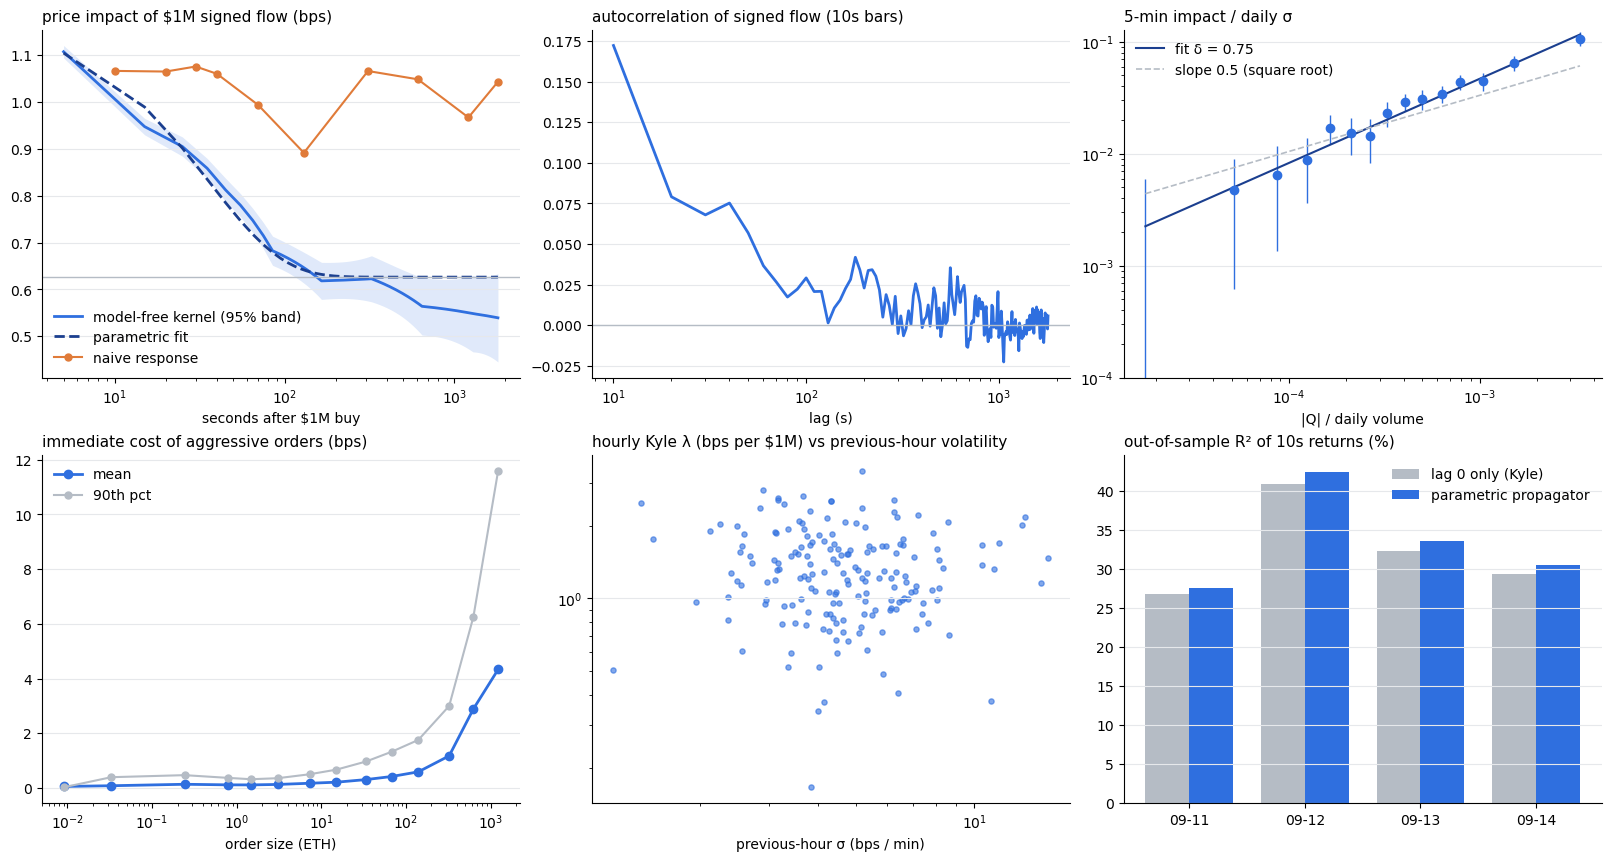

In [11]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8.5), constrained_layout=True)
ell = (np.arange(len(H_all)) + 0.5) * BAR_S

# (a) kernel H(l) with 95% band and exponential fit, vs naive response
ax[0, 0].fill_between(ell, H_all - 1.96 * se_all, H_all + 1.96 * se_all, color=C, alpha=0.15, lw=0)
ax[0, 0].plot(ell, H_all, color=C, lw=2, label="model-free kernel (95% band)")
ax[0, 0].plot(ell, EXP_ALL["H_inf"] + EXP_ALL["A"] * np.exp(-(np.arange(len(H_all))) * BAR_S / EXP_ALL["tau_s"]), color=D, lw=2, ls="--", label="parametric fit")
ax[0, 0].plot(RESP.lag_s, RESP.naive_response_bps_per_M, color=O, lw=1.5, marker="o", ms=5, label="naive response")
ax[0, 0].axhline(EXP_ALL["H_inf"], color=G, lw=1)
ax[0, 0].set_xscale("log"); ax[0, 0].set_xlabel("seconds after $1M buy"); ax[0, 0].legend(frameon=False)
style(ax[0, 0], "price impact of $1M signed flow (bps)")

# (b) flow autocorrelation
k = np.arange(1, len(acf))
ax[0, 1].plot(k * BAR_S, np.array(acf[1:]), color=C, lw=2); ax[0, 1].axhline(0, color=G, lw=1)
ax[0, 1].set_xscale("log"); ax[0, 1].set_xlabel("lag (s)"); style(ax[0, 1], f"autocorrelation of signed flow ({BAR_S}s bars)")

# (c) concavity
_, _, bm, _ = fit_concavity(CW[CW.W == DELTA_WINDOW_MIN])
row = CONC.set_index("window_min").loc[DELTA_WINDOW_MIN]
ax[0, 2].errorbar(bm.x, bm.y, yerr=1.96 * bm.se, fmt="o", color=C, ms=6, lw=1)
xx = np.logspace(np.log10(bm.x.min()), np.log10(bm.x.max()), 50)
ax[0, 2].plot(xx, row.Y * xx ** row.delta, color=D, lw=1.5, label=f"fit δ = {row.delta:.2f}")
ax[0, 2].plot(xx, row.Y * xx[len(xx) // 2] ** (row.delta - 0.5) * xx ** 0.5, color=G, lw=1.2, ls="--", label="slope 0.5 (square root)")
ax[0, 2].set_ylim(max(bm.y[bm.y > 0].min() / 3, 1e-4), None)
ax[0, 2].set_xscale("log"); ax[0, 2].set_yscale("log"); ax[0, 2].legend(frameon=False)
ax[0, 2].set_xlabel("|Q| / daily volume"); style(ax[0, 2], f"{DELTA_WINDOW_MIN}-min impact / daily σ")

# (d) immediate cost vs size
ic = IC[IC.orders >= 50]
ax[1, 0].plot(ic.qty_median, ic.cost_mean_bps, color=C, lw=2, marker="o", ms=6, label="mean")
ax[1, 0].plot(ic.qty_median, ic.cost_p90_bps, color=G, lw=1.5, marker="o", ms=5, label="90th pct")
ax[1, 0].set_xscale("log"); ax[1, 0].legend(frameon=False); ax[1, 0].set_xlabel("order size (ETH)")
style(ax[1, 0], "immediate cost of aggressive orders (bps)")

# (e) state dependence: lambda vs previous-hour volatility
ax[1, 1].scatter(st.sigma_1m_rv_bps_prev, st.kyle_lambda_bps_per_M, s=14, color=C, alpha=0.6)
ax[1, 1].set_xscale("log"); ax[1, 1].set_yscale("log"); ax[1, 1].set_xlabel("previous-hour σ (bps / min)")
style(ax[1, 1], "hourly Kyle λ (bps per $1M) vs previous-hour volatility")

# (f) out-of-sample R2
xi = np.arange(len(VAL)); w = 0.38
ax[1, 2].bar(xi - w / 2, 100 * VAL.R2_oos_lag0, w, color=G, label="lag 0 only (Kyle)")
ax[1, 2].bar(xi + w / 2, 100 * VAL.R2_oos_propagator, w, color=C, label="parametric propagator")
ax[1, 2].set_xticks(xi, [d[5:] for d in VAL.index]); ax[1, 2].legend(frameon=False)
style(ax[1, 2], f"out-of-sample R² of {BAR_S}s returns (%)")
fig.savefig(A_DIR / "impact_overview.png", dpi=120, bbox_inches="tight"); plt.show()

In [12]:
summary = {
    "bars": int(len(B)), "bar_s": BAR_S,
    "H0_bps_per_M": round(float(EXP_ALL["H0"]), 3), "H_inf_bps_per_M": round(float(EXP_ALL["H_inf"]), 3),
    "H_inf_95ci": [round(float(EXP_ALL["H_inf"] - 1.96 * EXP_ALL["se_H_inf"]), 3), round(float(EXP_ALL["H_inf"] + 1.96 * EXP_ALL["se_H_inf"]), 3)],
    "tau_95ci_s": [round(float(EXP_ALL["tau_lo"])), round(float(EXP_ALL["tau_hi"]))],
    "tau_s": round(float(EXP_ALL["tau_s"]), 1), "permanent_share": round(float(EXP_ALL["H_inf"] / EXP_ALL["H0"]), 3),
    "flow_acf_lag1": round(acf[1], 3),
    "delta_by_window": dict(zip(CONC.window_min.astype(str), CONC.delta.round(3))),
    "state_model_R2_in_sample": round(float(r2_all), 3),
    "state_coef": STATE.coef.round(3).to_dict(),
    "R2_oos_lag0_mean": round(float(VAL.R2_oos_lag0.mean()), 4),
    "R2_oos_propagator_mean": round(float(VAL.R2_oos_propagator.mean()), 4),
}
json.dump(summary, open(A_DIR / "impact_summary.json", "w"), indent=1, default=float)
for k_, v_ in summary.items(): print(f"{k_:28s} {v_}")

bars                         69120
bar_s                        10
H0_bps_per_M                 1.104
H_inf_bps_per_M              0.626
H_inf_95ci                   [0.516, 0.736]
tau_95ci_s                   [33, 40]
tau_s                        36.3
permanent_share              0.567
flow_acf_lag1                0.172
delta_by_window              {'1': 0.61, '5': 0.75, '15': 0.81, '30': 0.87}
state_model_R2_in_sample     0.022
state_coef                   {'const': 3.885, 'log_sigma_prev': -0.052, 'log_volume_prev': 0.021, 'log_depth_prev': -0.478}
R2_oos_lag0_mean             0.3233
R2_oos_propagator_mean       0.3354
